# Passo a passo · Regressão logística com scikit-learn
**Fundamentos de Machine Learning · Aula 3 · Prática guiada**

Neste notebook vamos percorrer **todas as fases** do treinamento de um classificador com regressão logística, na mesma ordem dos slides da aula:

1. Carregar a base de um arquivo CSV com o pandas
2. Visualizar, entender e limpar a base
3. Ver por que a regressão linear não serve para um alvo 0/1
4. Separar features (X) e alvo (y), treino e teste
5. Treinar o modelo com uma feature e desenhar a sigmoide
6. Transformar probabilidades em classes (limiar e fronteira de decisão)
7. Medir o erro com a log-loss
8. Ver o que o `fit` faz por dentro: gradiente descendente
9. Generalizar para duas features (fronteira no plano e superfície em 3D) e para várias

Execute as células na ordem, lendo os comentários de cada etapa.

## A base de dados: *Pima Indians Diabetes*

A base é originalmente do *National Institute of Diabetes and Digestive and Kidney Diseases* (NIDDK) e está disponível no Kaggle (*uciml/pima-indians-diabetes-database*). Cada linha é uma **paciente** (mulheres de origem Pima com 21 anos ou mais), 768 ao todo.

| Coluna | Significado |
|---|---|
| `Pregnancies` | número de gestações |
| `Glucose` | glicose no plasma 2 horas após um teste oral de tolerância (mg/dL) |
| `BloodPressure` | pressão diastólica (mm Hg) |
| `SkinThickness` | espessura da dobra cutânea do tríceps (mm) |
| `Insulin` | insulina sérica após 2 horas (μU/mL) |
| `BMI` | índice de massa corporal (kg/m²) |
| `DiabetesPedigreeFunction` | índice de histórico familiar de diabetes |
| `Age` | idade (anos) |
| `Outcome` | **alvo**: 1 = diabetes diagnosticada, 0 = não |

**Pergunta:** a partir dos exames de uma paciente, qual a probabilidade de ela ter diabetes?

**Como obter o arquivo:** baixe `diabetes.csv` no Kaggle [link](https://www.kaggle.com/datasets/mragpavank/diabetes) e salve-o em uma pasta `data/` ao lado deste notebook.

## Etapa 0 · Importar as bibliotecas

In [3]:
import numpy as np                                     # cálculos numéricos
import pandas as pd                                    # leitura e manipulação de tabelas
import matplotlib.pyplot as plt                        # gráficos

from sklearn.model_selection import train_test_split   # separação treino/teste
from sklearn.linear_model import LinearRegression      # só para a comparação da Etapa 3
from sklearn.linear_model import LogisticRegression    # o modelo desta aula
from sklearn.metrics import log_loss                   # a função de custo da aula

## Etapa 1 · Carregar o CSV com o pandas

In [4]:
df = pd.read_csv('../data/diabetes.csv')
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## Etapa 2 · Visualizar e limpar a base

Perguntas de sempre: quantas linhas e colunas? Os tipos estão corretos? Há valores ausentes? E, por ser um problema de **classificação**, uma pergunta nova: **quantos exemplos há em cada classe?**

In [5]:
print('Linhas e colunas:', df.shape)
df.info()

Linhas e colunas: (768, 9)
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [6]:
df['Outcome'].value_counts()      # quantas pacientes em cada classe

Outcome
0    500
1    268
Name: count, dtype: int64

In [7]:
df.describe().round(1)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.0,768.0,768.0,768.0,768.0,768.0,768.0,768.0,768.0
mean,3.8,120.9,69.1,20.5,79.8,32.0,0.5,33.2,0.3
std,3.4,32.0,19.4,16.0,115.2,7.9,0.3,11.8,0.5
min,0.0,0.0,0.0,0.0,0.0,0.0,0.1,21.0,0.0
25%,1.0,99.0,62.0,0.0,0.0,27.3,0.2,24.0,0.0
50%,3.0,117.0,72.0,23.0,30.5,32.0,0.4,29.0,0.0
75%,6.0,140.2,80.0,32.0,127.2,36.6,0.6,41.0,1.0
max,17.0,199.0,122.0,99.0,846.0,67.1,2.4,81.0,1.0


### Zeros que são, na verdade, valores ausentes

O `info()` diz que não há valores ausentes, mas o `describe()` mostra **mínimo 0** em `Glucose`, `BloodPressure` e `BMI`. Glicose zero, pressão zero e IMC zero são fisicamente impossíveis: nessa base, o zero foi usado para indicar **medida não registrada**.

In [8]:
colunas_medidas = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
(df[colunas_medidas] == 0).sum()      # quantos zeros em cada coluna

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

`SkinThickness` e `Insulin` têm zeros em boa parte das linhas. Se removêssemos essas linhas, perderíamos quase metade da base, então **deixamos essas duas colunas de fora** do modelo. Nas outras três, os zeros são poucos: trocamos por `NaN` e removemos as linhas.

In [9]:
df_limpo = df.drop(columns=['SkinThickness', 'Insulin']).copy()
df_limpo[['Glucose', 'BloodPressure', 'BMI']] = df_limpo[['Glucose', 'BloodPressure', 'BMI']].replace(0, np.nan)
df_limpo = df_limpo.dropna()

print(f'{len(df) - len(df_limpo)} linhas removidas; restam {len(df_limpo)}')

44 linhas removidas; restam 724


### Cada feature separada por classe

Um bom gráfico para classificação é o histograma de cada feature **separado por classe**. Quanto menos as duas cores se sobrepõem, mais aquela feature ajuda a separar as classes.

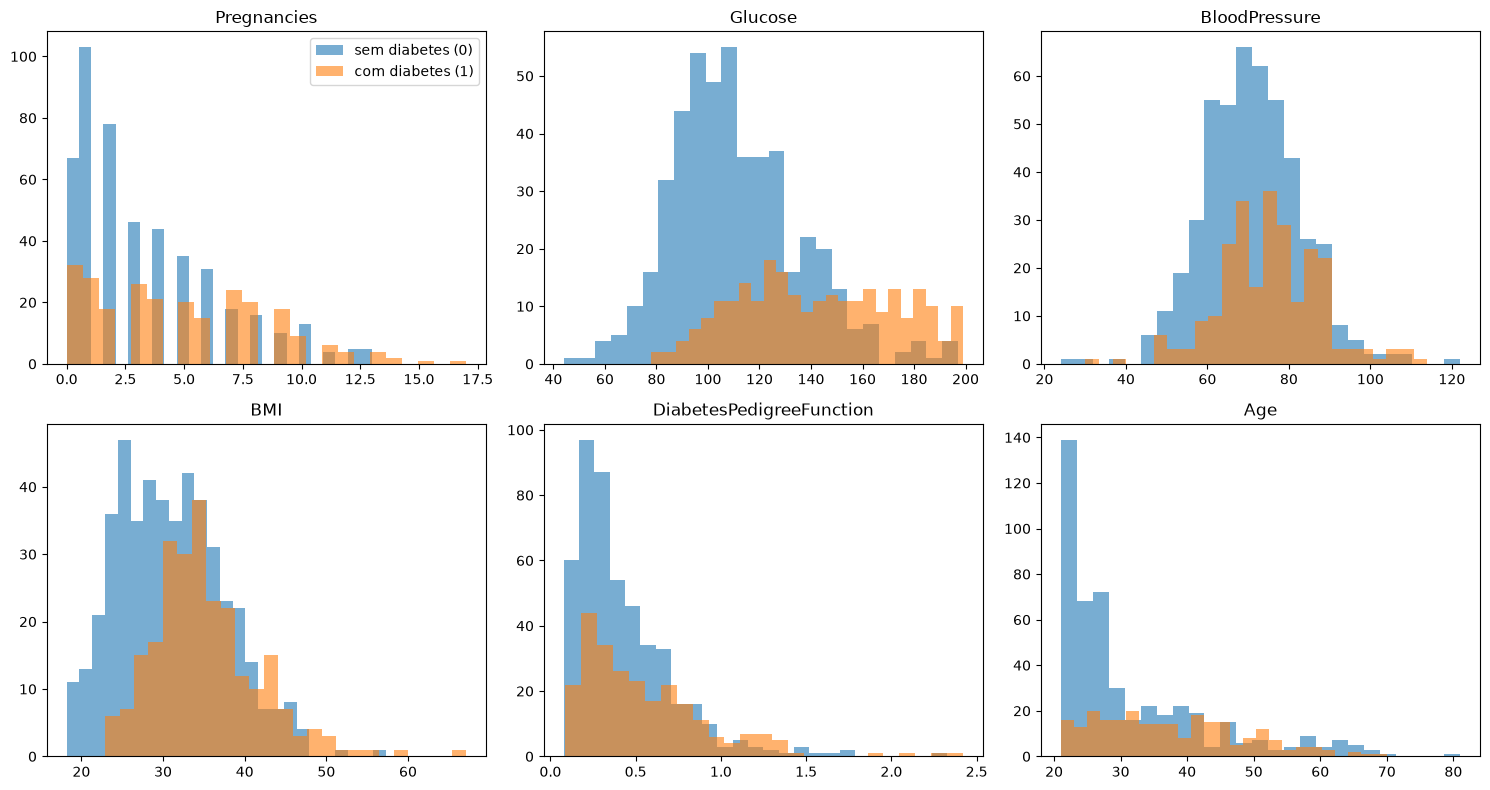

In [10]:
features = ['Pregnancies', 'Glucose', 'BloodPressure', 'BMI', 'DiabetesPedigreeFunction', 'Age']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), features):
    ax.hist(df_limpo.loc[df_limpo['Outcome'] == 0, col], bins=25, alpha=0.6, label='sem diabetes (0)')
    ax.hist(df_limpo.loc[df_limpo['Outcome'] == 1, col], bins=25, alpha=0.6, label='com diabetes (1)')
    ax.set_title(col)
axes[0, 0].legend()
plt.tight_layout()
plt.show()

In [11]:
df_limpo.groupby('Outcome')[features].mean().round(1)    # média de cada feature por classe

,Pregnancies,Glucose,BloodPressure,BMI,DiabetesPedigreeFunction,Age
Outcome,,,,,,
0,3.3,111.0,70.9,31.0,0.4,31.3
1,4.9,142.6,75.2,35.3,0.6,37.3


**O que observar:** `Glucose` é a feature que mais separa as classes. É com ela que vamos começar, como fizemos com a nota no exemplo da aula.

### O gráfico da aula: feature × alvo

Como nos slides, colocamos a feature no eixo x e o alvo (0 ou 1) no eixo y. Um pequeno deslocamento vertical aleatório (*jitter*) evita que os pontos fiquem todos sobrepostos.

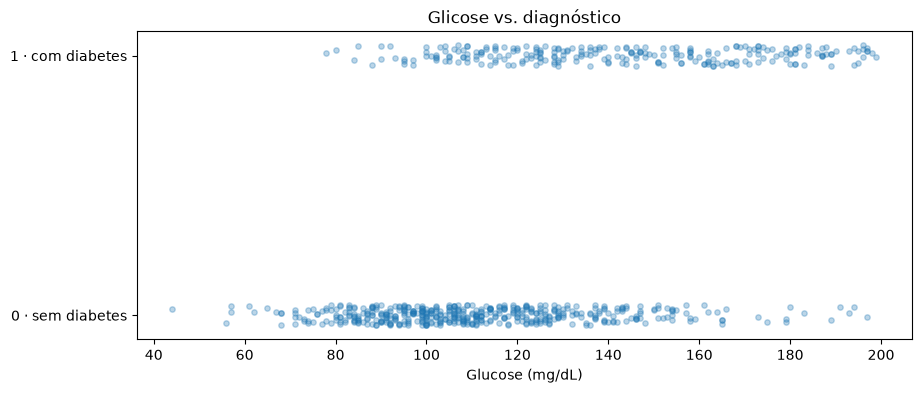

In [12]:
rng = np.random.default_rng(0)
jitter = rng.uniform(-0.04, 0.04, len(df_limpo))

plt.figure(figsize=(10, 4))
plt.scatter(df_limpo['Glucose'], df_limpo['Outcome'] + jitter, alpha=0.3, s=15)
plt.yticks([0, 1], ['0 · sem diabetes', '1 · com diabetes'])
plt.xlabel('Glucose (mg/dL)')
plt.title('Glicose vs. diagnóstico')
plt.show()

## Etapa 3 · Por que não usar a regressão linear?

Vamos ajustar uma reta aos pontos 0/1, como na aula 2, e olhar a menor e a maior previsão.

In [13]:
reta = LinearRegression().fit(df_limpo[['Glucose']], df_limpo['Outcome'])
previsto_reta = reta.predict(df_limpo[['Glucose']])

print(f'menor previsão: {previsto_reta.min():.3f}')
print(f'maior previsão: {previsto_reta.max():.3f}')
print(f'previsões fora de [0, 1]: {((previsto_reta < 0) | (previsto_reta > 1)).sum()}')

menor previsão: -0.244
maior previsão: 0.926
previsões fora de [0, 1]: 25


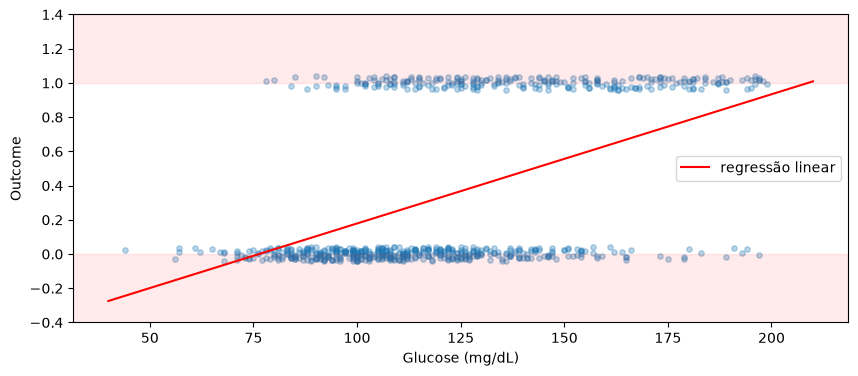

In [14]:
x_grade = np.linspace(40, 210, 200)

plt.figure(figsize=(10, 4))
plt.scatter(df_limpo['Glucose'], df_limpo['Outcome'] + jitter, alpha=0.3, s=15)
plt.plot(x_grade, reta.predict(pd.DataFrame({'Glucose': x_grade})), color='red', label='regressão linear')
plt.axhspan(1, 1.5, color='red', alpha=0.08); plt.axhspan(-0.5, 0, color='red', alpha=0.08)
plt.ylim(-0.4, 1.4)
plt.xlabel('Glucose (mg/dL)'); plt.ylabel('Outcome'); plt.legend()
plt.show()

A reta passa pelo meio dos dois grupos, mas a saída não tem limite: há pacientes com "probabilidade" negativa. As faixas vermelhas são valores que não podem ser probabilidades. É exatamente o problema do slide 3.

## Etapa 4 · X, y, treino e teste

Usamos `stratify=y` para que o treino e o teste tenham **a mesma proporção de pacientes com diabetes** da base completa. Em classificação, isso evita um teste com proporções distorcidas por acaso.

In [15]:
X = df_limpo[['Glucose']]          # 2D: uma única feature, por enquanto
y = df_limpo['Outcome']            # 1D

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print('Treino:', X_train.shape, '| Teste:', X_test.shape)
print(f'Proporção de diabetes: treino {y_train.mean():.3f} | teste {y_test.mean():.3f}')

Treino: (579, 1) | Teste: (145, 1)
Proporção de diabetes: treino 0.344 | teste 0.345


## Etapa 5 · Treinar o modelo com uma feature

O modelo é

$$p(\text{diabetes}) = \sigma(a + b \cdot \text{Glucose}) = \frac{1}{1 + e^{-(a + b \cdot \text{Glucose})}}$$

O `fit` encontra `a` e `b` que minimizam a **log-loss** no treino.

In [16]:
modelo = LogisticRegression()
modelo.fit(X_train, y_train)

a = modelo.intercept_[0]
b = modelo.coef_[0][0]
print(f'a (intercepto) = {a:.4f}')
print(f'b (Glucose)    = {b:.4f}')
print(f'centro da curva x* = -a/b = {-a / b:.1f} mg/dL')

a (intercepto) = -5.8552
b (Glucose)    = 0.0415
centro da curva x* = -a/b = 141.0 mg/dL


**Leitura:** `b > 0`, então a probabilidade de diabetes cresce com a glicose. O centro `x* = −a/b` é a glicose em que o modelo dá exatamente 50%.

### A sigmoide ajustada sobre os dados

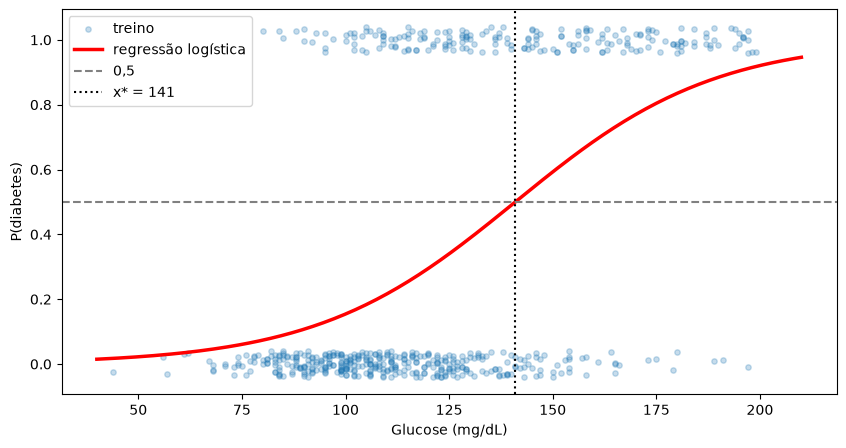

In [17]:
def sigmoide(z):
    return 1 / (1 + np.exp(-z))

plt.figure(figsize=(10, 5))
plt.scatter(X_train['Glucose'], y_train + rng.uniform(-0.04, 0.04, len(y_train)), alpha=0.25, s=15, label='treino')
plt.plot(x_grade, sigmoide(a + b * x_grade), color='red', linewidth=2.5, label='regressão logística')
plt.axhline(0.5, color='gray', linestyle='--', label='0,5')
plt.axvline(-a / b, color='black', linestyle=':', label=f'x* = {-a / b:.0f}')
plt.xlabel('Glucose (mg/dL)'); plt.ylabel('P(diabetes)'); plt.legend()
plt.show()

### Probabilidades para pacientes novas

- `predict_proba` devolve duas colunas: P(classe 0) e P(classe 1). Usamos a coluna `[:, 1]`.
- `predict` devolve a classe, usando o limiar 0,5.

In [18]:
novas = pd.DataFrame({'Glucose': [90, 120, 150, 180]})

novas['P(diabetes)'] = modelo.predict_proba(novas[['Glucose']])[:, 1].round(3)
novas['classe'] = modelo.predict(novas[['Glucose']])
novas

,Glucose,P(diabetes),classe
0,90,0.107,0
1,120,0.295,0
2,150,0.593,1
3,180,0.835,1


### Conferindo a fórmula na mão

`predict_proba` só aplica a reta e depois a sigmoide. Para glicose 150:

In [19]:
z = a + b * 150
print(f'z = a + b·150 = {z:.3f}')
print(f'σ(z) na mão    = {sigmoide(z):.3f}')
print(f'predict_proba  = {modelo.predict_proba(pd.DataFrame({"Glucose": [150]}))[0, 1]:.3f}')

z = a + b·150 = 0.375
σ(z) na mão    = 0.593
predict_proba  = 0.593


## Etapa 6 · De probabilidade a classe: o limiar

Com limiar 0,5, classificamos como diabetes quem tem `p ≥ 0,5`. Vamos contar, no conjunto de **teste**, os acertos e os dois tipos de erro:
- **diabetes não detectada**: a paciente tem diabetes (y = 1), mas o modelo previu 0;
- **alarme falso**: a paciente não tem (y = 0), mas o modelo previu 1.

In [20]:
p_test = modelo.predict_proba(X_test)[:, 1]

def contar(limiar):
    previsto = (p_test >= limiar).astype(int)
    return {
        'limiar': limiar,
        'fronteira (mg/dL)': round((np.log(limiar / (1 - limiar)) - a) / b, 1),
        'acertos': int((previsto == y_test).sum()),
        'diabetes não detectada': int(((previsto == 0) & (y_test == 1)).sum()),
        'alarme falso': int(((previsto == 1) & (y_test == 0)).sum()),
    }

pd.DataFrame([contar(l) for l in [0.3, 0.5, 0.7]])

,limiar,fronteira (mg/dL),acertos,diabetes não detectada,alarme falso
0,0.3,120.6,100,12,33
1,0.5,141.0,103,26,16
2,0.7,161.4,103,37,5


**Para discutir:** baixar o limiar move a fronteira para glicoses menores, detecta mais casos de diabetes e gera mais alarmes falsos. Em uma triagem médica, qual erro é mais caro? Essa escolha volta na aula de métricas de classificação.

## Etapa 7 · Medir o erro com a log-loss

$$J = -\frac{1}{n}\sum \big[\,y \log p + (1-y)\log(1-p)\,\big]$$

Calculamos na mão e comparamos com `sklearn.metrics.log_loss`. Como referência, comparamos também com um "modelo" ingênuo, que dá a mesma probabilidade (a proporção de diabetes no treino) para todas as pacientes.

In [21]:
J_mao = -np.mean(y_test * np.log(p_test) + (1 - y_test) * np.log(1 - p_test))
print(f'log-loss na mão     : {J_mao:.4f}')
print(f'log-loss do sklearn : {log_loss(y_test, p_test):.4f}')

p_ingenuo = np.full(len(y_test), y_train.mean())
print(f'log-loss ingênuo    : {log_loss(y_test, p_ingenuo):.4f}   (mesma probabilidade para todas)')

log-loss na mão     : 0.5587
log-loss do sklearn : 0.5587
log-loss ingênuo    : 0.6442   (mesma probabilidade para todas)


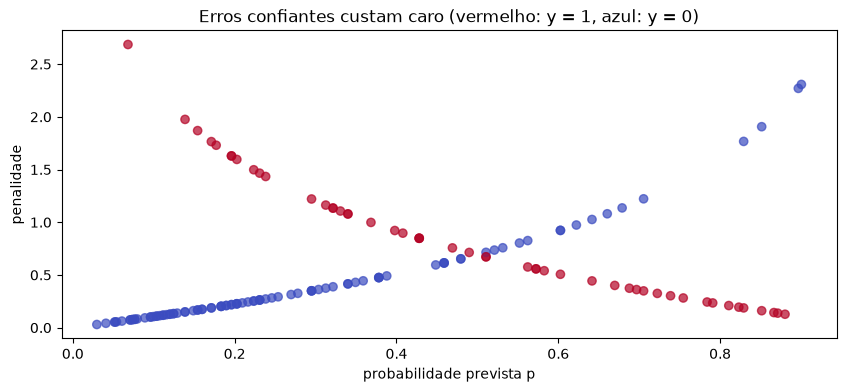

In [22]:
# Penalidade de cada paciente de teste: −log p se y = 1, −log(1 − p) se y = 0
penalidade = np.where(y_test == 1, -np.log(p_test), -np.log(1 - p_test))

plt.figure(figsize=(10, 4))
plt.scatter(p_test, penalidade, c=y_test, cmap='coolwarm', alpha=0.7)
plt.xlabel('probabilidade prevista p'); plt.ylabel('penalidade')
plt.title('Erros confiantes custam caro (vermelho: y = 1, azul: y = 0)')
plt.show()

## Etapa 8 · O que o `fit` faz por dentro: gradiente descendente

Não há fórmula fechada para `a` e `b`. O `fit` parte de um ponto e desce a superfície de custo. Vamos implementar o gradiente descendente da aula:

$$a \leftarrow a - \eta \cdot \text{média}(p - y) \qquad b \leftarrow b - \eta \cdot \text{média}((p - y)\cdot x)$$

Dois detalhes práticos:
1. **Padronizamos** a glicose (média 0, desvio 1). Sem isso, como `Glucose` vale centenas, o passo ideal seria minúsculo e a descida levaria muito tempo.
2. O scikit-learn adiciona por padrão uma pequena **regularização** ao custo (um termo `½·b²/n`). Incluímos o mesmo termo no gradiente de `b` para chegar exatamente ao mesmo resultado.

In [23]:
x_tr = X_train['Glucose'].values
media, desvio = x_tr.mean(), x_tr.std()
x_pad = (x_tr - media) / desvio            # glicose padronizada
y_tr = y_train.values
n = len(y_tr)

def custo(a_, b_):
    p_ = sigmoide(a_ + b_ * x_pad)
    return -np.mean(y_tr * np.log(p_) + (1 - y_tr) * np.log(1 - p_)) + 0.5 * b_**2 / n

a_gd, b_gd, eta = 0.0, 0.0, 0.5
historico = []
for i in range(300):
    p = sigmoide(a_gd + b_gd * x_pad)
    a_gd -= eta * np.mean(p - y_tr)
    b_gd -= eta * (np.mean((p - y_tr) * x_pad) + b_gd / n)
    historico.append(custo(a_gd, b_gd))

modelo_pad = LogisticRegression().fit(x_pad.reshape(-1, 1), y_tr)
print(f'gradiente descendente: a = {a_gd:.4f}, b = {b_gd:.4f}')
print(f'scikit-learn         : a = {modelo_pad.intercept_[0]:.4f}, b = {modelo_pad.coef_[0][0]:.4f}')

gradiente descendente: a = -0.7988, b = 1.2596
scikit-learn         : a = -0.7988, b = 1.2596


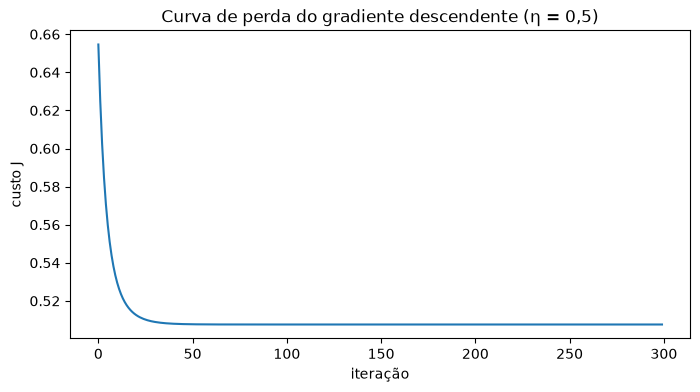

In [24]:
plt.figure(figsize=(8, 4))
plt.plot(historico)
plt.xlabel('iteração'); plt.ylabel('custo J')
plt.title('Curva de perda do gradiente descendente (η = 0,5)')
plt.show()

Experimente trocar `eta` por 0.05 e por 5 e rode as duas células de novo. Compare as curvas de perda com o slide 12 da aula.

## Etapa 9 · Duas features: fronteira no plano e superfície em 3D

Agora usamos `Glucose` e `BMI`:

$$p = \sigma(a + b_1 \cdot \text{Glucose} + b_2 \cdot \text{BMI})$$

A fronteira `p = 0,5` acontece quando `a + b₁·Glucose + b₂·BMI = 0`, que é **uma reta** no plano (Glucose, BMI).

In [25]:
X2 = df_limpo[['Glucose', 'BMI']]
X2_train, X2_test, y_train, y_test = train_test_split(
    X2, y, test_size=0.2, random_state=42, stratify=y)    # mesma separação de antes

modelo2 = LogisticRegression().fit(X2_train, y_train)
a2 = modelo2.intercept_[0]
b1, b2 = modelo2.coef_[0]
print(f'a = {a2:.4f} | b1 (Glucose) = {b1:.4f} | b2 (BMI) = {b2:.4f}')

a = -8.4561 | b1 (Glucose) = 0.0387 | b2 (BMI) = 0.0897


### 9.1 A fronteira de decisão no plano

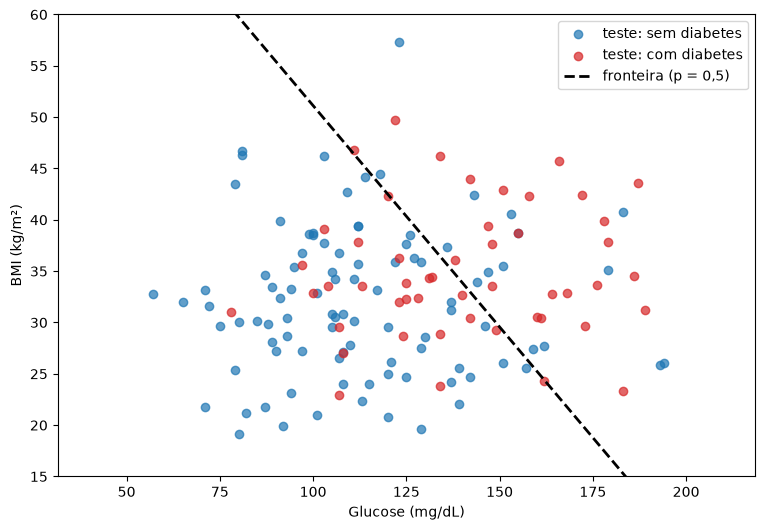

In [26]:
glu = np.linspace(40, 210, 100)
bmi_fronteira = -(a2 + b1 * glu) / b2          # isolando BMI em a + b1·G + b2·BMI = 0

plt.figure(figsize=(9, 6))
for classe, cor, nome in [(0, 'tab:blue', 'sem diabetes'), (1, 'tab:red', 'com diabetes')]:
    sel = y_test == classe
    plt.scatter(X2_test.loc[sel, 'Glucose'], X2_test.loc[sel, 'BMI'], c=cor, alpha=0.7, label=f'teste: {nome}')
plt.plot(glu, bmi_fronteira, 'k--', linewidth=2, label='fronteira (p = 0,5)')
plt.ylim(15, 60)
plt.xlabel('Glucose (mg/dL)'); plt.ylabel('BMI (kg/m²)'); plt.legend()
plt.show()

A reta tem inclinação negativa: com IMC maior, a glicose necessária para o modelo prever diabetes é menor.

### 9.2 A superfície p(Glucose, BMI) em 3D

A sigmoide transforma o plano `z = a + b₁·Glucose + b₂·BMI` numa **rampa** que vai de 0 a 1. As pacientes ficam no piso (0) ou no teto (1).

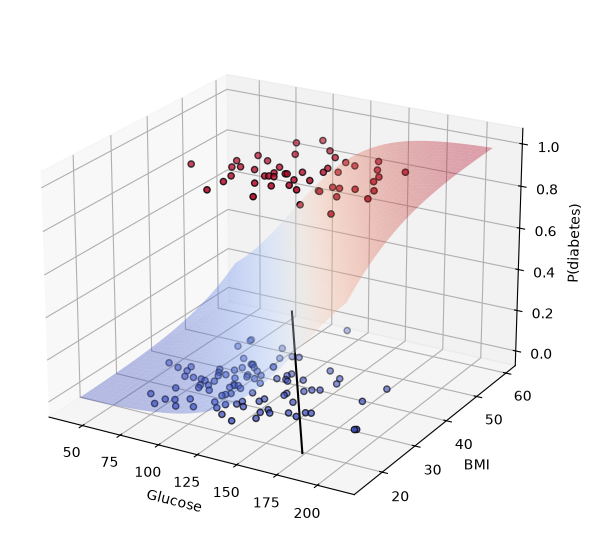

In [27]:
G_g, B_g = np.meshgrid(np.linspace(40, 210, 40), np.linspace(15, 60, 40))
P_g = sigmoide(a2 + b1 * G_g + b2 * B_g)

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(projection='3d')
ax.plot_surface(G_g, B_g, P_g, alpha=0.35, cmap='coolwarm')
ax.scatter(X2_test['Glucose'], X2_test['BMI'], y_test, c=y_test, cmap='coolwarm', edgecolor='k', s=20)
ax.contour(G_g, B_g, P_g, levels=[0.5], colors='k', offset=0)   # fronteira projetada no piso
ax.set_xlabel('Glucose'); ax.set_ylabel('BMI'); ax.set_zlabel('P(diabetes)')
ax.view_init(elev=22, azim=-60)       # mude elev e azim para girar o gráfico
plt.show()

### 9.3 Todas as features

Com p features, a fronteira é um **hiperplano**. O código é o mesmo: só muda a lista de colunas. Aumentamos `max_iter` porque as features têm escalas muito diferentes e o otimizador precisa de mais iterações.

In [28]:
X6 = df_limpo[features]
X6_train, X6_test, y_train, y_test = train_test_split(
    X6, y, test_size=0.2, random_state=42, stratify=y)

modelo6 = LogisticRegression(max_iter=1000).fit(X6_train, y_train)
pd.Series(modelo6.coef_[0], index=features).round(4)

Pregnancies                 0.1724
Glucose                     0.0373
BloodPressure              -0.0030
BMI                         0.1023
DiabetesPedigreeFunction    1.2314
Age                         0.0089
dtype: float64

In [29]:
comparacao = pd.DataFrame({
    'features': ['Glucose', 'Glucose + BMI', 'todas (6)'],
    'log-loss teste': [log_loss(y_test, modelo.predict_proba(X_test)[:, 1]),
                       log_loss(y_test, modelo2.predict_proba(X2_test)[:, 1]),
                       log_loss(y_test, modelo6.predict_proba(X6_test)[:, 1])],
    'acertos (limiar 0,5)': [(modelo.predict(X_test) == y_test).sum(),
                             (modelo2.predict(X2_test) == y_test).sum(),
                             (modelo6.predict(X6_test) == y_test).sum()],
})
comparacao.round(4)

,features,log-loss teste,"acertos (limiar 0,5)"
0,Glucose,0.5587,103
1,Glucose + BMI,0.5437,105
2,todas (6),0.5927,102


## Resumo: a receita completa

```python
df = pd.read_csv('arquivo.csv')                              # 1. carregar
df.info(); df.describe(); df['alvo'].value_counts()          # 2. visualizar (e limpar)
X, y = df[[...features...]], df['alvo']                      # 3. X (2D) e y (1D, com 0 e 1)
X_train, X_test, y_train, y_test = train_test_split(         # 4. treino e teste, estratificado
    X, y, test_size=0.2, random_state=42, stratify=y)
modelo = LogisticRegression().fit(X_train, y_train)          # 5. treinar (minimiza a log-loss)
modelo.intercept_, modelo.coef_                              # 6. interpretar a e b
p = modelo.predict_proba(X_test)[:, 1]                       # 7. probabilidade
classe = (p >= 0.5).astype(int)                              # 8. classe, com o limiar escolhido
log_loss(y_test, p)                                          # 9. erro
```

Na atividade, você vai aplicar esta mesma receita a outra base de dados.